In [ ]:
pip install pandas numpy matplotlib seaborn jupyter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 77.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 108.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.9/947.9 kB 30.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [jupyter]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("dataset.csv")

print("Dataset loaded successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'dataset.csv'

In [ ]:
df = pd.read_csv("/dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print(df.head())
print(df.shape)
print(df.info())

   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   


In [ ]:

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
df.info()
print(df.describe())

   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   


In [ ]:
# Remove unnecessary index column if present
if "Unnamed: 0" in df.columns:
    df.drop("Unnamed: 0", axis=1, inplace=True)

# Convert duration from milliseconds to minutes
df["duration_min"] = df["duration_ms"] / 60000

# Convert explicit column into boolean
df["explicit"] = df["explicit"].astype(bool)

# Round duration to 2 decimal places
df["duration_min"] = df["duration_min"].round(2)

print(df.head())

print("Data transformation completed!")

                 track_id                 artists  \
0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   
3  Can't Help Falling In Love          71       201933     False   
4   

In [ ]:
# Check missing values
print("Missing values before handling:")

print(df.isnull().sum())

# Select numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Replace missing numerical values with their mean
for col in numeric_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mean())

# Check missing values after handling
print("\nMissing values after handling:")

print(df.isnull().sum())

Missing values before handling:
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_min        0
dtype: int64

Missing values after handling:
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_min        0

In [ ]:
#Insight 1
top_songs = df.nlargest(10, "popularity")

print(top_songs[["track_name", "artists", "popularity"]])

                                  track_name                  artists  \
20001              Unholy (feat. Kim Petras)     Sam Smith;Kim Petras   
81051              Unholy (feat. Kim Petras)     Sam Smith;Kim Petras   
51664  Quevedo: Bzrp Music Sessions, Vol. 52         Bizarrap;Quevedo   
20008                        I'm Good (Blue)  David Guetta;Bebe Rexha   
30003                        I'm Good (Blue)  David Guetta;Bebe Rexha   
67356                             La Bachata            Manuel Turizo   
68303                             La Bachata            Manuel Turizo   
81210                        I'm Good (Blue)  David Guetta;Bebe Rexha   
88410                             La Bachata            Manuel Turizo   
89411                             La Bachata            Manuel Turizo   

       popularity  
20001         100  
81051         100  
51664          99  
20008          98  
30003          98  
67356          98  
68303          98  
81210          98  
88410          9

In [ ]:
#Insight 2
average_popularity = df["popularity"].mean()

print("Average song popularity:", average_popularity)

Average song popularity: 33.2385350877193


In [ ]:
#Insight 3: Top 10 genres
top_genres = df["track_genre"].value_counts().head(10)

print(top_genres)

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64


In [ ]:
#Insight 4: Average energy and danceability
print("Average Energy:", df["energy"].mean())

print("Average Danceability:", df["danceability"].mean())

Average Energy: 0.6413827583964913
Average Danceability: 0.5668000657894736


In [ ]:
#Insight 5: Longest songs
longest_songs = df.nlargest(10, "duration_min")

print(longest_songs[
    ["track_name", "artists", "duration_min"]
])

                                          track_name            artists  \
73617                       Unity (Voyage Mix) Pt. 1         Tale Of Us   
10935         Crossing Wires 002 - Continuous DJ Mix          Timo Maas   
10984         Crossing Wires 002 - Continuous DJ Mix          Timo Maas   
24348          The Lab 03 - Continuous DJ Mix Part 1       Seth Troxler   
73840            Amnesia Ibiza Underground 10 DJ Mix          Loco Dice   
13344     House of Om - Mark Farina - Continuous Mix        Mark Farina   
13245                 Live In Tokyo - Continuous Mix        Mark Farina   
13195                        Greenhouse Construction        Mark Farina   
27926   NQ State of Mind, Vol. 1 - Continuous DJ Mix  Lenzman;Dan Stezo   
101390                            Ocean Waves Sounds       Ocean Sounds   

        duration_min  
73617          87.29  
10935          79.82  
10984          79.82  
24348          78.84  
73840          76.06  
13344          74.13  
13245        

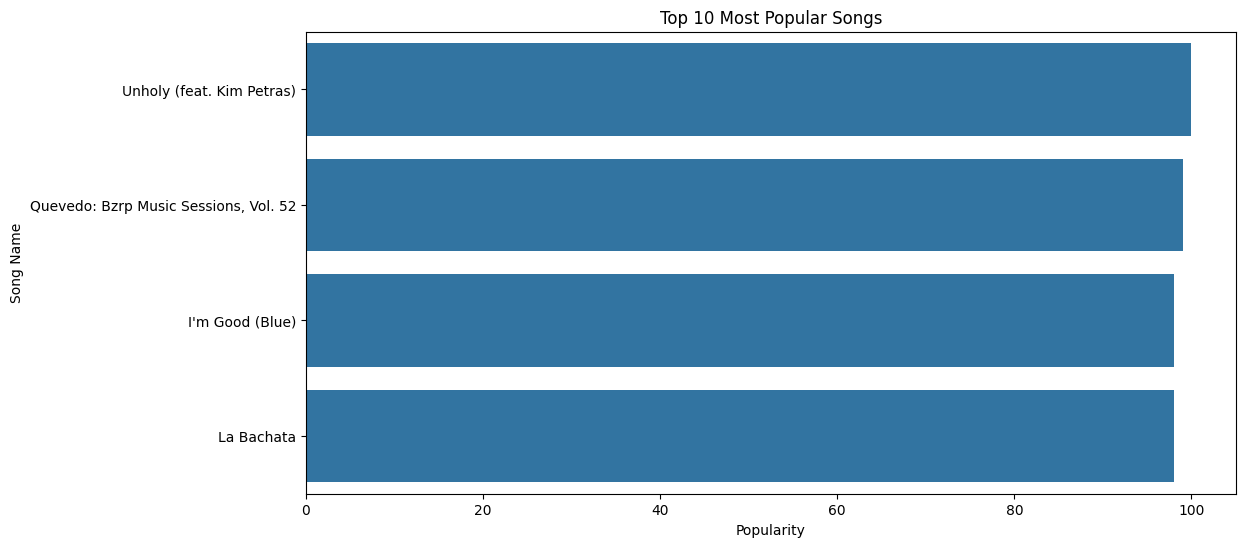

In [ ]:
#Graphs
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_songs,
    x="popularity",
    y="track_name"
)

plt.title("Top 10 Most Popular Songs")
plt.xlabel("Popularity")
plt.ylabel("Song Name")

plt.show()

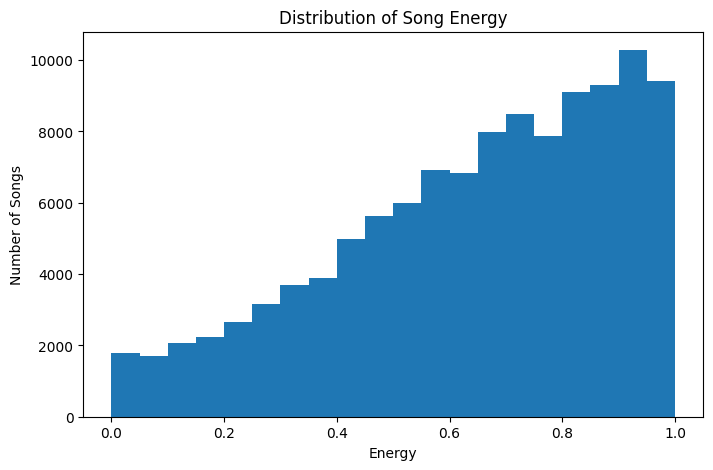

In [ ]:
#Graph 2: Distribution of song energy
plt.figure(figsize=(8, 5))

plt.hist(df["energy"], bins=20)

plt.title("Distribution of Song Energy")
plt.xlabel("Energy")
plt.ylabel("Number of Songs")

plt.show()

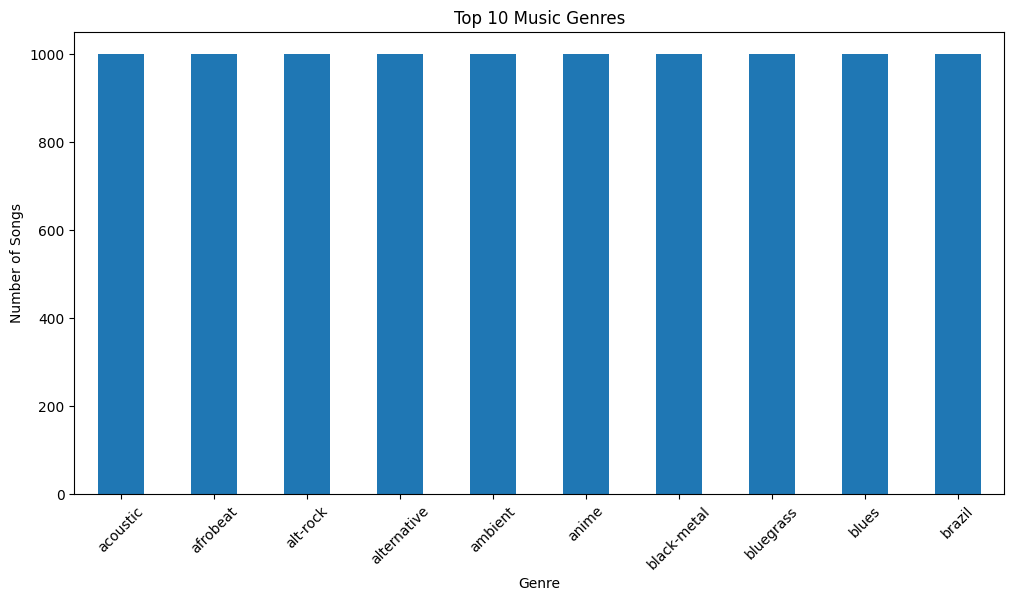

In [ ]:
#Graph 3: Top 10 music genres
plt.figure(figsize=(12, 6))

top_genres.plot(kind="bar")

plt.title("Top 10 Music Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Songs")

plt.xticks(rotation=45)

plt.show()

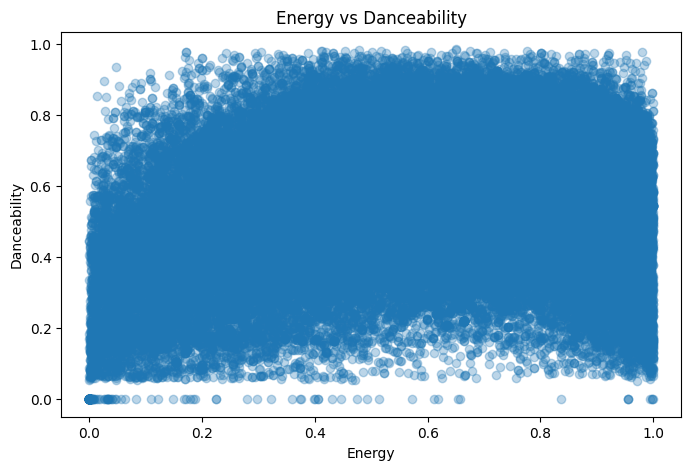

In [24]:
#Graph 4: Energy vs Danceability
plt.figure(figsize=(8, 5))

plt.scatter(
    df["energy"],
    df["danceability"],
    alpha=0.3
)

plt.title("Energy vs Danceability")
plt.xlabel("Energy")
plt.ylabel("Danceability")

plt.show()